# XGBoost binary — pointwise ranking proof @ `rating >= 2` (retrain-threshold-gte2)

This notebook is **self-contained**: every piece of model, feature, training, and
evaluation logic lives inline below. The only shared import is the raw data loader
`movielens.data` (loading `ratings.dat` / `movies.dat` / `users.dat`).

Binary classification over the full interaction set with the positive-label cutoff moved
to `rating >= 2`: rating `1 -> 0`, ratings `2, 3, 4, 5 -> 1`. Candidates are ranked by
predicted P(positive) and evaluated with `precision@10` / `recall@10` / `NDCG@10`
against held-out positive (`rating >= 2`) items. An **inline popularity baseline**
(top-k movies by training rating count) is compared at the same `>= 2` relevance. The
trained model is logged to MLflow under the
**`test`** alias.


In [1]:
%matplotlib inline
import hashlib
import os
import subprocess
import sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt


def repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "movielens").is_dir() and (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("repository root not found")


ROOT = repo_root()
sys.path.insert(0, str(ROOT / "src"))

import mlflow
import numpy as np
import pandas as pd
from xgboost import XGBClassifier

from movielens.data import RAW_DIR, extract_release_year, load_movies, load_ratings, load_users

SEED = 42
K = 10
EXPERIMENT = "xgboost"
REGISTRY_NAME = "xgboost-v1"
INTENT = "xgboost-binary-v1-gte2"
MLFLOW_URI = (ROOT / "mlflow" / "mlruns").as_uri()

os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")

plt.rcParams["figure.figsize"] = (8, 3.5)


2026/10/18 23:39:44 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Franco\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Model / feature / evaluation helpers

All ranking logic is defined inline. The features are fully tabular (no embeddings).


In [2]:
@dataclass
class Lookups:
    feature_names: list[str]
    user_index: dict[int, int]
    movie_index: dict[int, int]
    movie_ids: np.ndarray
    user_age: np.ndarray
    user_gender: np.ndarray
    user_occupation: np.ndarray
    movie_genres: np.ndarray
    movie_year: np.ndarray
    user_mean: np.ndarray
    item_mean: np.ndarray
    user_count: np.ndarray
    item_count: np.ndarray


def build_dataset():
    ratings = load_ratings()
    movies = load_movies()
    users = load_users()
    binary = ratings.copy()
    binary["label"] = (binary["rating"] >= 2).astype(np.int64)
    return ratings, binary, movies, users


def chronological_split(binary, train_frac=0.8, val_frac=0.1):
    df = binary.sort_values(
        ["timestamp", "user_id", "movie_id"], kind="stable"
    ).reset_index(drop=True)
    n = len(df)
    train_end = int(train_frac * n)
    val_end = int((train_frac + val_frac) * n)
    return df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:]


def build_lookups(movies, users, train_full):
    genre_list = sorted(movies["genres"].str.split("|").explode().unique())
    occupation_list = sorted(users["occupation"].unique())
    gender_list = sorted(users["gender"].unique())

    user_ids = np.sort(users["user_id"].to_numpy())
    movie_ids = np.sort(movies["movie_id"].to_numpy())
    user_index = {int(u): i for i, u in enumerate(user_ids)}
    movie_index = {int(m): i for i, m in enumerate(movie_ids)}

    user_df = users.set_index("user_id").loc[user_ids]
    user_age = user_df["age"].to_numpy(dtype=np.float32)
    user_gender = pd.get_dummies(user_df["gender"]).reindex(
        columns=gender_list, fill_value=0
    ).to_numpy(dtype=np.float32)
    user_occupation = pd.get_dummies(user_df["occupation"]).reindex(
        columns=occupation_list, fill_value=0
    ).to_numpy(dtype=np.float32)

    movie_df = movies.set_index("movie_id").loc[movie_ids]
    movie_genres = pd.get_dummies(
        movie_df["genres"].str.split("|").explode()
    ).groupby(level=0).max().reindex(index=movie_ids, columns=genre_list, fill_value=0)
    movie_genres = movie_genres.to_numpy(dtype=np.float32)
    year = extract_release_year(movie_df["title"]).to_numpy(dtype=np.float32)
    year = np.nan_to_num(year, nan=-1.0)

    global_mean = float(train_full["rating"].mean())

    user_stats = train_full.groupby("user_id")["rating"].agg(["mean", "count"])
    item_stats = train_full.groupby("movie_id")["rating"].agg(["mean", "count"])

    user_mean = np.full(len(user_ids), global_mean, dtype=np.float32)
    user_count = np.zeros(len(user_ids), dtype=np.float32)
    for u, i in user_index.items():
        if u in user_stats.index:
            user_mean[i] = user_stats.at[u, "mean"]
            user_count[i] = user_stats.at[u, "count"]

    item_mean = np.full(len(movie_ids), global_mean, dtype=np.float32)
    item_count = np.zeros(len(movie_ids), dtype=np.float32)
    for m, i in movie_index.items():
        if m in item_stats.index:
            item_mean[i] = item_stats.at[m, "mean"]
            item_count[i] = item_stats.at[m, "count"]

    feature_names = (
        ["age"]
        + [f"gender_{g}" for g in gender_list]
        + [f"occupation_{o}" for o in occupation_list]
        + [f"genre_{g}" for g in genre_list]
        + [
            "release_year",
            "user_mean_rating",
            "item_mean_rating",
            "user_rating_count",
            "item_rating_count",
        ]
    )

    return Lookups(
        feature_names=feature_names,
        user_index=user_index,
        movie_index=movie_index,
        movie_ids=movie_ids,
        user_age=user_age,
        user_gender=user_gender,
        user_occupation=user_occupation,
        movie_genres=movie_genres,
        movie_year=year,
        user_mean=user_mean,
        item_mean=item_mean,
        user_count=user_count,
        item_count=item_count,
    )


def build_features(user_ids, movie_ids, lookups):
    ui = pd.Series(user_ids).map(lookups.user_index).to_numpy(dtype=np.int64)
    mi = pd.Series(movie_ids).map(lookups.movie_index).to_numpy(dtype=np.int64)

    cols = [
        lookups.user_age[ui].reshape(-1, 1),
        lookups.user_gender[ui],
        lookups.user_occupation[ui],
        lookups.movie_genres[mi],
        lookups.movie_year[mi].reshape(-1, 1),
        lookups.user_mean[ui].reshape(-1, 1),
        lookups.item_mean[mi].reshape(-1, 1),
        lookups.user_count[ui].reshape(-1, 1),
        lookups.item_count[mi].reshape(-1, 1),
    ]
    return np.hstack(cols).astype(np.float32)


def score_candidates(model, test_users, lookups, train_rated, batch_size=1000):
    n_movies = len(lookups.movie_ids)
    movie_arr = lookups.movie_ids
    recs = {}

    for start in range(0, len(test_users), batch_size):
        batch = test_users[start : start + batch_size]
        n_u = len(batch)
        seen = np.zeros((n_u, n_movies), dtype=bool)
        for i, u in enumerate(batch):
            for m in train_rated.get(u, set()):
                j = lookups.movie_index.get(m)
                if j is not None:
                    seen[i, j] = True

        counts = (~seen).sum(axis=1)
        total = int(counts.sum())
        uid_all = np.empty(total, dtype=np.int64)
        mid_all = np.empty(total, dtype=np.int64)
        pos = 0
        for i in range(n_u):
            cols = np.flatnonzero(~seen[i])
            c = int(cols.size)
            uid_all[pos : pos + c] = batch[i]
            mid_all[pos : pos + c] = movie_arr[cols]
            pos += c

        probs = model.predict_proba(build_features(uid_all, mid_all, lookups))[:, 1]

        pos = 0
        for i, u in enumerate(batch):
            c = int(counts[i])
            if c == 0:
                recs[u] = []
                continue
            sub = probs[pos : pos + c]
            mid = mid_all[pos : pos + c]
            order = np.argsort(-sub, kind="stable")
            recs[u] = mid[order].tolist()
            pos += c

    return recs


def precision_at_k(relevant, recommended, k=K):
    scores = []
    for rel, rec in zip(relevant, recommended):
        top = set(rec[:k])
        scores.append(len(top & rel) / k)
    return float(np.mean(scores)) if scores else 0.0


def recall_at_k(relevant, recommended, k=K):
    scores = []
    for rel, rec in zip(relevant, recommended):
        top = set(rec[:k])
        scores.append(len(top & rel) / len(rel) if rel else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def ndcg_at_k(relevant, recommended, k=K):
    scores = []
    for rel, rec in zip(relevant, recommended):
        top = rec[:k]
        dcg = 0.0
        for i, m in enumerate(top):
            if m in rel:
                dcg += 1.0 / np.log2(i + 2)
        n = min(k, len(rel))
        idcg = sum(1.0 / np.log2(i + 2) for i in range(n))
        scores.append(dcg / idcg if idcg else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def data_version_hash():
    digest = hashlib.sha1((RAW_DIR / "ratings.dat").read_bytes()).hexdigest()
    return digest[:12]


def git_sha():
    out = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return out.stdout.strip()


## 1. EDA

Rating distribution, class balance, dataset shape, sparsity, and class imbalance.


n_users: 6040
n_movies: 3706
n_ratings (all 1-5): 1000209
sparsity (observed / users x movies): 0.0447
full dataset ratings (all 1-5): 1000209

label_1_count (2+3+4+5-star): 944035
label_0_count (1-star): 56174
label_1_ratio: 0.9438
imbalance ratio (2+3+4+5-star / 1-star): 16.81


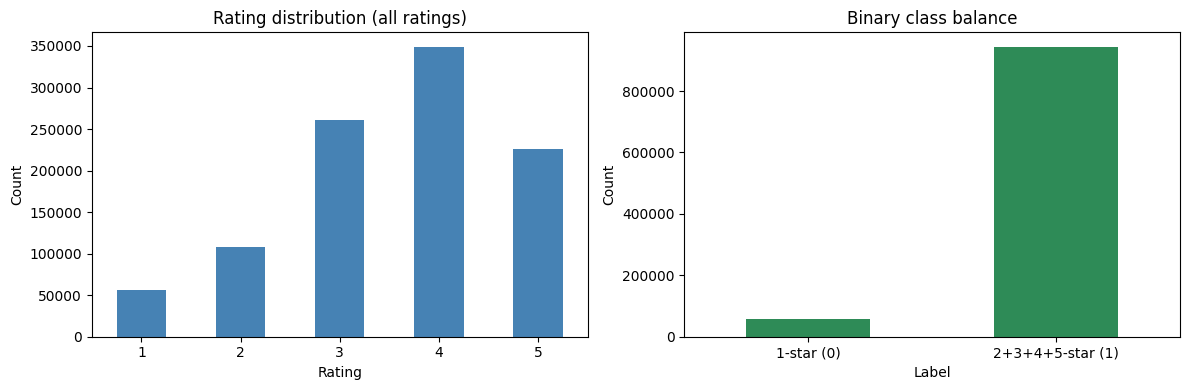

In [3]:
ratings, binary, movies, users = build_dataset()

n_ratings = len(binary)
n_users = binary["user_id"].nunique()
n_movies = binary["movie_id"].nunique()
sparsity = n_ratings / (n_users * n_movies)

label_1_count = int((binary["label"] == 1).sum())
label_0_count = int((binary["label"] == 0).sum())
label_1_ratio = label_1_count / n_ratings

print("n_users:", n_users)
print("n_movies:", n_movies)
print("n_ratings (all 1-5):", n_ratings)
print("sparsity (observed / users x movies):", round(sparsity, 4))
print("full dataset ratings (all 1-5):", len(ratings))
print()
print("label_1_count (2+3+4+5-star):", label_1_count)
print("label_0_count (1-star):", label_0_count)
print("label_1_ratio:", round(label_1_ratio, 4))
print("imbalance ratio (2+3+4+5-star / 1-star):", round(label_1_count / label_0_count, 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rating_counts = ratings["rating"].value_counts().sort_index()
rating_counts.plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Rating distribution (all ratings)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

binary["label"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="seagreen", rot=0)
axes[1].set_title("Binary class balance")
axes[1].set_xlabel("Label")
axes[1].set_xticklabels(["1-star (0)", "2+3+4+5-star (1)"])
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 2. Feature construction

- **user**: age (numeric), gender (one-hot), occupation (one-hot).
- **item**: genres (multi-hot, one column per genre), release year (parsed from title,
  missing → −1).
- **interaction**: `user_mean_rating`, `item_mean_rating`, `user_rating_count`,
  `item_rating_count` — computed **on training folds only** (`train_full`) to avoid
  leakage. Unseen users/items fall back to the global mean and count 0.

`build_lookups` precomputes per-row index maps and frozen feature vectors so candidate
scoring is a vectorized gather (no per-row Python loops).


## 3. Split — chronological 80/10/10

The binary interaction set is sorted by `timestamp` (stable) and split globally
80/10/10. Chronological ordering is used because real deployment must not leak the
future: train stats and the model only see past interactions, and the test set's
2+3+4+5-star items are the genuinely held-out ground truth for ranking evaluation.


In [4]:
train, val, test = chronological_split(binary)
train_end = int(train["timestamp"].max())
train_full = ratings[ratings["timestamp"] <= train_end]

lookups = build_lookups(movies, users, train_full)

X_train = build_features(train["user_id"].to_numpy(), train["movie_id"].to_numpy(), lookups)
y_train = train["label"].to_numpy()
X_val = build_features(val["user_id"].to_numpy(), val["movie_id"].to_numpy(), lookups)
y_val = val["label"].to_numpy()

print("split sizes train/val/test:", len(train), len(val), len(test))
print("n features:", len(lookups.feature_names))
print("train timestamp cutoff:", train_end)


split sizes train/val/test: 800167 100021 100021
n features: 47
train timestamp cutoff: 975768738


## 4. Training — XGBoost binary classifier

Fixed seed 42, logistic objective. `scale_pos_weight` is set to `n_neg / n_pos` so the
loss re-weights the minority (1-star) class. Hyperparameters are logged to MLflow.


In [5]:
n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
scale_pos_weight = n_neg / n_pos if n_pos else 1.0

params = dict(
    max_depth=6,
    n_estimators=100,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
)

print("train positives:", n_pos, "negatives:", n_neg)
print("scale_pos_weight =", round(scale_pos_weight, 4))

model = XGBClassifier(**params)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)


train positives: 754829 negatives: 45338
scale_pos_weight = 0.0601


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

## 5. Feature importance

Per-feature mean gain (default `feature_importances_`), ranked descending. Interaction
count/mean features and release year are expected to dominate because they carry the
strongest signal about rating tendency.


top 20 features by gain:
          feature     gain
 item_mean_rating 0.299999
 user_mean_rating 0.106936
    occupation_11 0.030849
    genre_Western 0.027839
    genre_Musical 0.025412
    genre_Mystery 0.020661
         gender_F 0.020173
     occupation_5 0.018955
user_rating_count 0.018243
     occupation_4 0.016417
     genre_Horror 0.016175
    occupation_18 0.016134
     occupation_2 0.015958
     release_year 0.015887
     occupation_1 0.015301
   genre_Thriller 0.015041
    occupation_20 0.014811
    occupation_16 0.014702
     genre_Action 0.014588
     occupation_7 0.014517


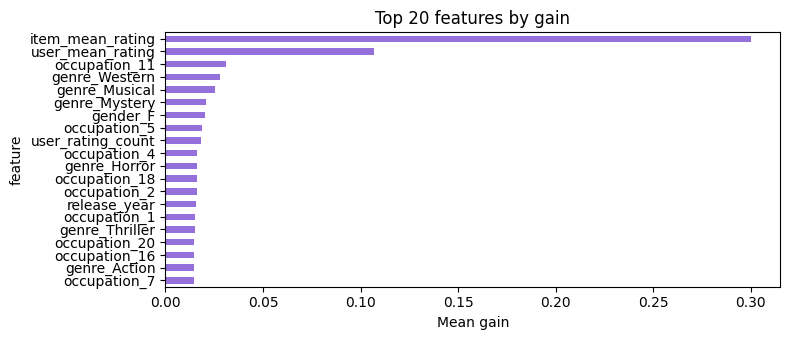

In [6]:
importances = model.feature_importances_
imp_df = pd.DataFrame({"feature": lookups.feature_names, "gain": importances})
imp_df = imp_df.sort_values("gain", ascending=False).reset_index(drop=True)
print("top 20 features by gain:")
print(imp_df.head(20).to_string(index=False))

imp_df.head(20).set_index("feature")["gain"].plot(kind="barh", color="mediumpurple")
plt.gca().invert_yaxis()
plt.title("Top 20 features by gain")
plt.xlabel("Mean gain")
plt.tight_layout()
plt.show()


## 6. Evaluation — precision@10 / recall@10 / NDCG@10

For each test user: `relevant` = their held-out positive (`rating >= 2`) movies;
candidates = all movies not rated by that user in training, scored by predicted
P(positive) and ranked descending. `precision@10 = |top10 ∩ relevant| / 10`;
`recall@10 = |top10 ∩ relevant| / |relevant|`; `NDCG@10` over the same top-10 with binary
relevance. All three are averaged over test users with a non-empty relevant set (users
with no held-out positive items are excluded from the mean). An inline popularity
baseline is compared in the next cell.


In [7]:
test_users = sorted(test["user_id"].unique().tolist())
relevant = {
    u: set(test.loc[(test["user_id"] == u) & (test["label"] == 1), "movie_id"])
    for u in test_users
}
train_rated = train_full.groupby("user_id")["movie_id"].apply(set).to_dict()

eval_users = [u for u in test_users if relevant[u]]
n_excluded = len(test_users) - len(eval_users)

model_recs = score_candidates(model, eval_users, lookups, train_rated)

rel_list = [relevant[u] for u in eval_users]
model_rec_list = [model_recs[u] for u in eval_users]

metrics = {
    "precision@10": precision_at_k(rel_list, model_rec_list, K),
    "recall@10": recall_at_k(rel_list, model_rec_list, K),
    "ndcg@10": ndcg_at_k(rel_list, model_rec_list, K),
}

summary = pd.DataFrame(
    {
        "precision@10": [metrics["precision@10"]],
        "recall@10": [metrics["recall@10"]],
        "ndcg@10": [metrics["ndcg@10"]],
    },
    index=["model"],
)
print("test users (total):", len(test_users))
print("test users excluded (empty relevant set):", n_excluded)
print("test users evaluated:", len(eval_users))
print()
print(summary.to_string())


test users (total): 1209
test users excluded (empty relevant set): 1
test users evaluated: 1208

       precision@10  recall@10   ndcg@10
model      0.059603    0.01095  0.062298


## 6b. Popularity baseline (inline) — comparison

Re-added per directive: an **inline** popularity baseline (top-k movies by training
rating count, excluding each user's train-rated items) at the same `rating >= 2`
relevance and on the same 1208 test users. It is model-independent (one set of numbers
shared across all retrained models) and is **not** registered to MLflow.


In [ ]:
def popularity_recommendations(eval_users, train_rated, train_full, k=K):
    pop_rank = train_full.groupby("movie_id").size().sort_values(ascending=False).index.to_numpy()
    recs = {}
    for u in eval_users:
        rated = train_rated.get(u, set())
        top = [int(m) for m in pop_rank if m not in rated][:k]
        recs[u] = top
    return recs


pop_recs = popularity_recommendations(eval_users, train_rated, train_full)
pop_rec_list = [pop_recs[u] for u in eval_users]

pop_metrics = {
    "precision@10": precision_at_k(rel_list, pop_rec_list, K),
    "recall@10": recall_at_k(rel_list, pop_rec_list, K),
    "ndcg@10": ndcg_at_k(rel_list, pop_rec_list, K),
}

comparison = pd.DataFrame(
    {
        "precision@10": [metrics["precision@10"], pop_metrics["precision@10"], metrics["precision@10"] - pop_metrics["precision@10"]],
        "recall@10": [metrics["recall@10"], pop_metrics["recall@10"], metrics["recall@10"] - pop_metrics["recall@10"]],
        "ndcg@10": [metrics["ndcg@10"], pop_metrics["ndcg@10"], metrics["ndcg@10"] - pop_metrics["ndcg@10"]],
    },
    index=["model", "popularity baseline", "delta (model - popularity)"],
)
print(comparison.round(6).to_string())


## 7. Log to MLflow (under the `test` alias)

Metrics, params, and the model artifact are logged; tags `code_version`, `data_version`,
and `intent` are set. The newly registered version is given the **`test`** alias (never
`Staging`/`Production`).


In [8]:
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.tracking.MlflowClient()

metric_log = {k.replace("@", "_at_"): v for k, v in metrics.items()}

with mlflow.start_run() as active_run:
    run_id = active_run.info.run_id
    mlflow.log_params(params)
    mlflow.log_metrics(metric_log)
    mlflow.set_tags(
        {
            "code_version": git_sha(),
            "data_version": data_version_hash(),
            "intent": INTENT,
        }
    )
    info = mlflow.xgboost.log_model(model, name="model", registered_model_name=REGISTRY_NAME)
    version = info.registered_model_version
    client.set_registered_model_alias(REGISTRY_NAME, "test", version)

print("run_id:", run_id)
print("registered version:", version)
print("test alias ->", client.get_model_version_by_alias(REGISTRY_NAME, "test").version)
print("code_version:", git_sha())
print("data_version:", data_version_hash())


Successfully registered model 'xgboost-v1'.
Created version '1' of model 'xgboost-v1'.


run_id: 643118880c944a8dbac59937d2171752
registered version: 1
test alias -> 1
code_version: 172af8dd3b087c250ce2c8aaaa38104e548b3a39
data_version: 28770e0e10e2
